<a href="https://colab.research.google.com/github/gayatrip1310/studystress-insights/blob/main/studystress_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score)
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


In [ ]:
from google.colab import files
uploaded = files.upload()
df_raw = pd.read_csv(list(uploaded.keys())[0])
print(df_raw.shape)
df_raw.head()

Saving students_raw.csv to students_raw.csv
(500, 25)


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,...,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,...,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,...,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,...,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15
3,STU2004,22,F,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,...,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,...,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74


In [ ]:
print(df_raw.columns.tolist())
df_raw.info()
df_raw.describe()

['student_id', 'age', 'gender', 'year_of_study', 'major_category', 'residence_type', 'chronotype', 'avg_bedtime_hour', 'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours', 'pre_sleep_screen_time_min', 'daily_screen_time_hours', 'primary_device', 'device_free_before_bed', 'caffeine_drinks_per_day', 'naps_per_week', 'sleep_quality_score', 'exercise_days_per_week', 'energy_level', 'concentration_difficulty', 'weekly_study_hours', 'class_attendance_percent', 'has_part_time_job', 'semester_type', 'cgpa']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 500 non-null    object 
 1   age                        500 non-null    int64  
 2   gender                     500 non-null    object 
 3   year_of_study              500 non-null    int64  
 4   major_category             500 non-null    obj

,age,year_of_study,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,cgpa
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,494.000000,500.000000,485.000000,486.000000,500.0000,500.000000,493.000000
mean,20.260000,2.954000,12.778200,6.608200,1.540600,38.388000,5.827000,1.502000,1.458000,7.271255,3.666000,5.758763,5.176955,16.5714,79.247200,2.833834
std,1.994079,1.405644,10.772656,1.435784,0.965441,23.573478,2.046193,1.273279,1.331082,2.131409,2.277019,1.981722,2.033119,6.9279,11.983513,0.334771
min,17.000000,1.000000,0.000000,1.500000,-1.000000,0.000000,0.500000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.0000,34.600000,1.890000
25%,19.000000,2.000000,1.100000,5.700000,0.900000,22.000000,4.475000,1.000000,0.000000,6.000000,2.000000,4.000000,4.000000,12.1000,70.775000,2.620000
50%,20.000000,3.000000,21.500000,6.600000,1.500000,35.500000,5.800000,1.000000,1.000000,7.000000,4.000000,6.000000,5.000000,16.3000,79.800000,2.850000
75%,22.000000,4.000000,22.800000,7.700000,2.200000,54.000000,7.200000,2.000000,2.000000,9.000000,6.000000,7.000000,7.000000,20.3250,87.925000,3.050000
max,27.000000,5.000000,24.000000,10.500000,4.400000,240.000000,19.500000,7.000000,7.000000,10.000000,7.000000,10.000000,10.000000,88.5000,100.000000,3.950000


In [ ]:
print(df_raw.shape)
for i, c in enumerate(df_raw.columns):
    print(i, c, "|", df_raw[c].dtype, "| missing:", df_raw[c].isna().sum())

(500, 25)
0 student_id | object | missing: 0
1 age | int64 | missing: 0
2 gender | object | missing: 0
3 year_of_study | int64 | missing: 0
4 major_category | object | missing: 0
5 residence_type | object | missing: 0
6 chronotype | object | missing: 0
7 avg_bedtime_hour | float64 | missing: 0
8 avg_sleep_hours_weekday | float64 | missing: 0
9 weekend_sleep_delta_hours | float64 | missing: 0
10 pre_sleep_screen_time_min | int64 | missing: 0
11 daily_screen_time_hours | float64 | missing: 0
12 primary_device | object | missing: 0
13 device_free_before_bed | object | missing: 9
14 caffeine_drinks_per_day | int64 | missing: 0
15 naps_per_week | int64 | missing: 0
16 sleep_quality_score | float64 | missing: 6
17 exercise_days_per_week | int64 | missing: 0
18 energy_level | float64 | missing: 15
19 concentration_difficulty | float64 | missing: 14
20 weekly_study_hours | float64 | missing: 0
21 class_attendance_percent | float64 | missing: 0
22 has_part_time_job | object | missing: 0
23 seme

In [ ]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,500.0,20.260000,1.994079,17.00,19.000,20.00,22.000,27.00
year_of_study,500.0,2.954000,1.405644,1.00,2.000,3.00,4.000,5.00
avg_bedtime_hour,500.0,12.778200,10.772656,0.00,1.100,21.50,22.800,24.00
avg_sleep_hours_weekday,500.0,6.608200,1.435784,1.50,5.700,6.60,7.700,10.50
weekend_sleep_delta_hours,500.0,1.540600,0.965441,-1.00,0.900,1.50,2.200,4.40
pre_sleep_screen_time_min,500.0,38.388000,23.573478,0.00,22.000,35.50,54.000,240.00
daily_screen_time_hours,500.0,5.827000,2.046193,0.50,4.475,5.80,7.200,19.50
caffeine_drinks_per_day,500.0,1.502000,1.273279,0.00,1.000,1.00,2.000,7.00
naps_per_week,500.0,1.458000,1.331082,0.00,0.000,1.00,2.000,7.00
sleep_quality_score,494.0,7.271255,2.131409,1.00,6.000,7.00,9.000,10.00


In [ ]:
df = df_raw.copy()
print("Start:", df.shape)

# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Fix bedtime: after-midnight times (0 to 11.9) become 24 to 35.9
df["bedtime_adj"] = np.where(df["avg_bedtime_hour"] < 12,
                             df["avg_bedtime_hour"] + 24,
                             df["avg_bedtime_hour"])

# 3. Fill missing values: median for numbers, most common for text
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df["device_free_before_bed"] = df["device_free_before_bed"].fillna(
    df["device_free_before_bed"].mode()[0])

# 4. Clean gender spelling (used for charts only, not for the model)
g = df["gender"].str.strip().str.lower().replace({"f": "female", "m": "male"})
df["gender"] = g.str.title()
print(df["gender"].value_counts())

# 5. Remove impossible values
before = len(df)
df = df[df["daily_screen_time_hours"].between(0, 16)]
df = df[df["weekly_study_hours"].between(0, 60)]
df = df[df["avg_sleep_hours_weekday"].between(3, 12)]
df = df.reset_index(drop=True)
print("Outlier rows removed:", before - len(df))
print("End:", df.shape)

# 6. Choose features
FEATURES = ["avg_sleep_hours_weekday", "bedtime_adj", "daily_screen_time_hours",
            "pre_sleep_screen_time_min", "caffeine_drinks_per_day",
            "exercise_days_per_week", "weekly_study_hours", "class_attendance_percent"]

PROFILE_COLS = FEATURES + ["weekend_sleep_delta_hours", "sleep_quality_score",
                           "energy_level", "concentration_difficulty", "cgpa"]

df[FEATURES].describe().T.round(2)

Start: (500, 25)
gender
Female               242
Male                 233
Non-Binary            13
Prefer Not To Say     12
Name: count, dtype: int64
Outlier rows removed: 6
End: (494, 26)


,count,mean,std,min,25%,50%,75%,max
avg_sleep_hours_weekday,494.0,6.65,1.39,3.1,5.70,6.7,7.70,10.5
bedtime_adj,494.0,23.80,1.46,19.0,22.60,23.7,24.90,27.9
daily_screen_time_hours,494.0,5.79,1.96,0.5,4.43,5.8,7.20,11.4
pre_sleep_screen_time_min,494.0,38.31,23.59,0.0,22.00,35.0,53.75,240.0
caffeine_drinks_per_day,494.0,1.49,1.27,0.0,1.00,1.0,2.00,7.0
exercise_days_per_week,494.0,3.66,2.28,0.0,2.00,4.0,6.00,7.0
weekly_study_hours,494.0,16.41,6.14,0.0,12.02,16.3,20.30,39.1
class_attendance_percent,494.0,79.33,11.91,34.6,70.82,79.8,87.98,100.0


In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print(X.shape)
print("means:", X.mean(axis=0).round(2))
print("stds :", X.std(axis=0).round(2))

(494, 8)
means: [ 0. -0. -0.  0. -0.  0.  0. -0.]
stds : [1. 1. 1. 1. 1. 1. 1. 1.]


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,3330.720,0.147,2.232,91.773
1,3,3067.470,0.113,2.356,70.792
2,4,2851.079,0.112,2.208,63.070
3,5,2690.398,0.110,2.089,57.326
4,6,2566.552,0.107,1.952,52.685
5,7,2465.696,0.107,1.972,48.927
6,8,2366.349,0.110,1.885,46.523


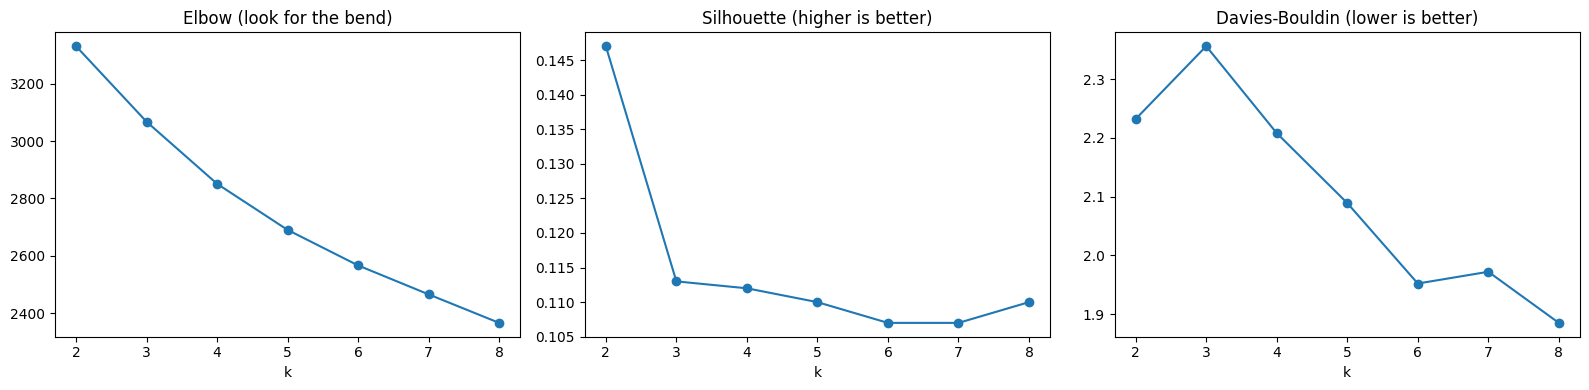

In [ ]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({"k": k,
                 "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
scores = pd.DataFrame(rows).round(3)
display(scores)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(scores.k, scores.inertia, "o-");        ax[0].set_title("Elbow (look for the bend)")
ax[1].plot(scores.k, scores.silhouette, "o-");     ax[1].set_title("Silhouette (higher is better)")
ax[2].plot(scores.k, scores.davies_bouldin, "o-"); ax[2].set_title("Davies-Bouldin (lower is better)")
for a in ax:
    a.set_xlabel("k")
plt.tight_layout()
plt.savefig("k_selection.png", dpi=150)
plt.show()

Cluster sizes:
 0     93
1    123
2    137
3    141
Name: count, dtype: int64


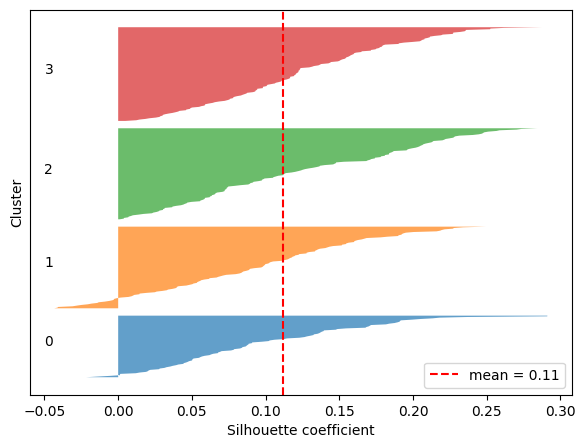

In [ ]:
K = 4

def silhouette_plot(X, labels):
    k = len(set(labels))
    sil = silhouette_samples(X, labels)
    fig, ax = plt.subplots(figsize=(7, 5))
    y_lower = 10
    for i in range(k):
        vals = np.sort(sil[labels == i])
        y_upper = y_lower + len(vals)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.7)
        ax.text(-0.05, y_lower + 0.5 * len(vals), str(i))
        y_lower = y_upper + 10
    ax.axvline(sil.mean(), color="red", linestyle="--", label=f"mean = {sil.mean():.2f}")
    ax.set_xlabel("Silhouette coefficient")
    ax.set_ylabel("Cluster")
    ax.set_yticks([])
    ax.legend()
    plt.savefig("silhouette_plot.png", dpi=150)
    plt.show()

labels_km = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X)
print("Cluster sizes:\n", pd.Series(labels_km).value_counts().sort_index())
silhouette_plot(X, labels_km)

In [ ]:
ag_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
candidates = {"K-Means": labels_km, "Agglomerative": ag_labels}
for eps in [1.5, 2.0, 2.5, 3.0]:
    candidates[f"DBSCAN eps={eps}"] = DBSCAN(eps=eps, min_samples=10).fit_predict(X)

results = []
for name, labels in candidates.items():
    mask = labels != -1                         # -1 means "noise" in DBSCAN
    n_cl = len(set(labels[mask]))
    row = {"model": name, "clusters": n_cl, "noise_%": round((~mask).mean() * 100, 1)}
    if n_cl >= 2:
        row["silhouette"] = round(silhouette_score(X[mask], labels[mask]), 3)
        row["davies_bouldin"] = round(davies_bouldin_score(X[mask], labels[mask]), 3)
        row["calinski_harabasz"] = round(calinski_harabasz_score(X[mask], labels[mask]), 1)
    results.append(row)

comparison = pd.DataFrame(results)
comparison

,model,clusters,noise_%,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,4,0.0,0.112,2.208,63.1
1,Agglomerative,4,0.0,0.058,2.646,45.2
2,DBSCAN eps=1.5,3,93.7,0.362,1.063,26.2
3,DBSCAN eps=2.0,1,14.0,NaN,NaN,NaN
4,DBSCAN eps=2.5,1,2.8,NaN,NaN,NaN
5,DBSCAN eps=3.0,1,0.4,NaN,NaN,NaN


cluster,0,1,2,3
avg_sleep_hours_weekday,5.87,5.41,7.56,7.35
bedtime_adj,23.86,25.14,22.75,23.61
daily_screen_time_hours,4.50,6.57,6.10,5.67
pre_sleep_screen_time_min,30.99,62.82,28.36,31.43
caffeine_drinks_per_day,2.45,1.61,1.04,1.20
exercise_days_per_week,2.77,3.90,1.77,5.87
weekly_study_hours,17.91,16.10,14.78,17.27
class_attendance_percent,68.87,76.85,83.45,84.38
weekend_sleep_delta_hours,1.85,1.87,1.28,1.24
sleep_quality_score,6.63,5.48,8.53,8.16


chronotype,Early Bird,Intermediate,Night Owl
cluster,,,
0,0.18,0.57,0.25
1,0.01,0.24,0.76
2,0.62,0.32,0.06
3,0.35,0.52,0.13


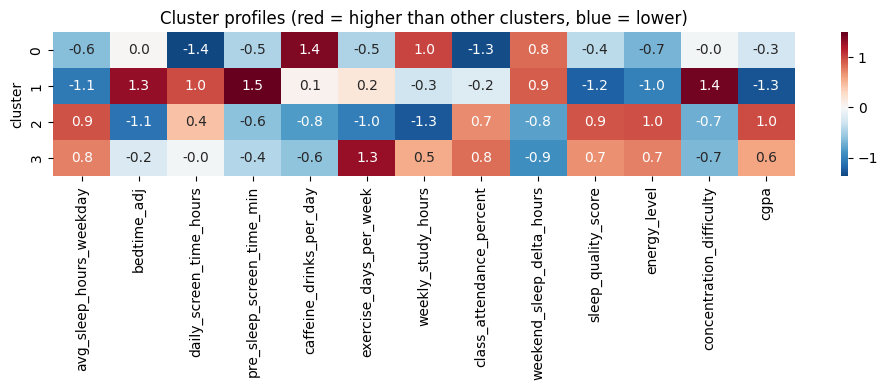

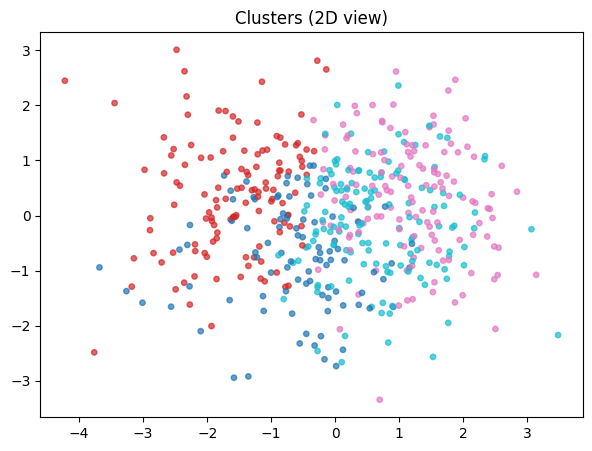

In [ ]:
final_km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
df["cluster"] = final_km.labels_

profile = df.groupby("cluster")[PROFILE_COLS].mean().round(2)
profile["students"] = df["cluster"].value_counts().sort_index()
profile["share_%"] = (profile["students"] / len(df) * 100).round(1)
display(profile.T)

display(pd.crosstab(df["cluster"], df["chronotype"], normalize="index").round(2))

z = (profile[PROFILE_COLS] - profile[PROFILE_COLS].mean()) / profile[PROFILE_COLS].std()
plt.figure(figsize=(10, 4))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Cluster profiles (red = higher than other clusters, blue = lower)")
plt.tight_layout()
plt.savefig("profile_heatmap.png", dpi=150)
plt.show()

pcs = PCA(n_components=2, random_state=42).fit_transform(X)
plt.figure(figsize=(7, 5))
plt.scatter(pcs[:, 0], pcs[:, 1], c=df["cluster"], cmap="tab10", s=15, alpha=0.7)
plt.title("Clusters (2D view)")
plt.savefig("pca_clusters.png", dpi=150)
plt.show()


In [ ]:
CLUSTER_NAMES = {
    0: "Caffeine-reliant short sleeper",
    1: "Screen-heavy night owl",
    2: "Rested early bird, low activity",
    3: "Active and balanced",
}
df["cluster_name"] = df["cluster"].map(CLUSTER_NAMES)
df["cluster_name"].value_counts()

,count
cluster_name,
Active and balanced,141
"Rested early bird, low activity",137
Screen-heavy night owl,123
Caffeine-reliant short sleeper,93


In [ ]:
os.makedirs("models", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(final_km, "models/kmeans_model.pkl")
with open("models/config.json", "w") as f:
    json.dump({"features": FEATURES, "cluster_names": CLUSTER_NAMES}, f)

df.drop(columns=["student_id", "age"]).to_csv("data/processed/clustered_students.csv", index=False)

!zip -r outputs.zip models data/processed *.png
from google.colab import files
files.download("outputs.zip")

  adding: models/ (stored 0%)
  adding: models/config.json (deflated 38%)
  adding: models/kmeans_model.pkl (deflated 62%)
  adding: models/scaler.pkl (deflated 34%)
  adding: data/processed/ (stored 0%)
  adding: data/processed/clustered_students.csv (deflated 80%)
  adding: k_selection.png (deflated 11%)
  adding: pca_clusters.png (deflated 3%)
  adding: profile_heatmap.png (deflated 9%)
  adding: silhouette_plot.png (deflated 13%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>